In [1]:
import pandas as pd

path = "../data/raw/"
orders    = pd.read_csv(path + "olist_orders_dataset.csv")
items     = pd.read_csv(path + "olist_order_items_dataset.csv")
products  = pd.read_csv(path + "olist_products_dataset.csv")
category  = pd.read_csv(path + "product_category_name_translation.csv")
customers = pd.read_csv(path + "olist_customers_dataset.csv")

In [2]:
cat_sales = (items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
                  .merge(category, on="product_category_name", how="left"))

top_cat = (cat_sales.groupby("product_category_name_english")["price"]
                    .sum().sort_values(ascending=False).head(10).round(0))
top_cat

product_category_name_english
health_beauty            1258681.0
watches_gifts            1205006.0
bed_bath_table           1036989.0
sports_leisure            988049.0
computers_accessories     911954.0
furniture_decor           729762.0
cool_stuff                635291.0
housewares                632249.0
auto                      592720.0
garden_tools              485256.0
Name: price, dtype: float64

In [3]:
state_sales = (items.merge(orders[["order_id", "customer_id"]], on="order_id")
                    .merge(customers[["customer_id", "customer_state"]], on="customer_id"))

top_state = (state_sales.groupby("customer_state")["price"]
                        .sum().sort_values(ascending=False).head(10).round(0))
top_state

customer_state
SP    5202955.0
RJ    1824093.0
MG    1585308.0
RS     750304.0
PR     683084.0
SC     520553.0
BA     511350.0
DF     302604.0
GO     294592.0
ES     275037.0
Name: price, dtype: float64

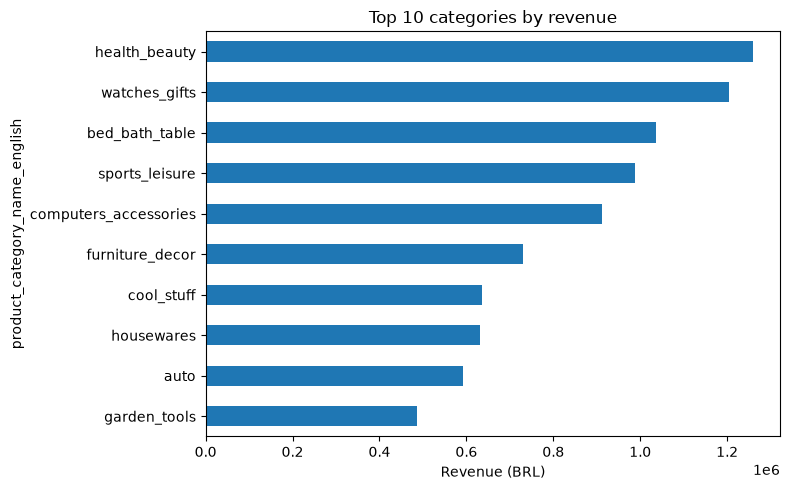

In [4]:
import matplotlib.pyplot as plt

top_cat.sort_values().plot(kind="barh", figsize=(8, 5), title="Top 10 categories by revenue")
plt.xlabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

In [5]:
cust_orders = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")
delivered_orders = cust_orders[cust_orders["order_status"] == "delivered"]

orders_per_customer = delivered_orders.groupby("customer_unique_id")["order_id"].nunique()

total_customers = len(orders_per_customer)
repeat_customers = (orders_per_customer > 1).sum()

print("Unique customers:", total_customers)
print("Repeat customers:", repeat_customers)
print(f"Repeat rate: {repeat_customers / total_customers * 100:.1f}%")

Unique customers: 93358
Repeat customers: 2801
Repeat rate: 3.0%


In [6]:
orders["order_month"] = pd.to_datetime(orders["order_purchase_timestamp"]).dt.strftime("%Y-%m")

m = items.merge(orders[["order_id", "order_month"]], on="order_id")

monthly = m.groupby("order_month").agg(
    revenue=("price", "sum"),
    orders=("order_id", "nunique")
)
monthly["avg_order_value"] = monthly["revenue"] / monthly["orders"]

monthly = monthly.loc["2017-01":"2018-08"].round(2)
monthly

,revenue,orders,avg_order_value
order_month,,,
2017-01,120312.87,789,152.49
2017-02,247303.02,1733,142.70
2017-03,374344.30,2641,141.74
2017-04,359927.23,2391,150.53
2017-05,506071.14,3660,138.27
2017-06,433038.60,3217,134.61
2017-07,498031.48,3969,125.48
2017-08,573971.68,4293,133.70
2017-09,624401.69,4243,147.16


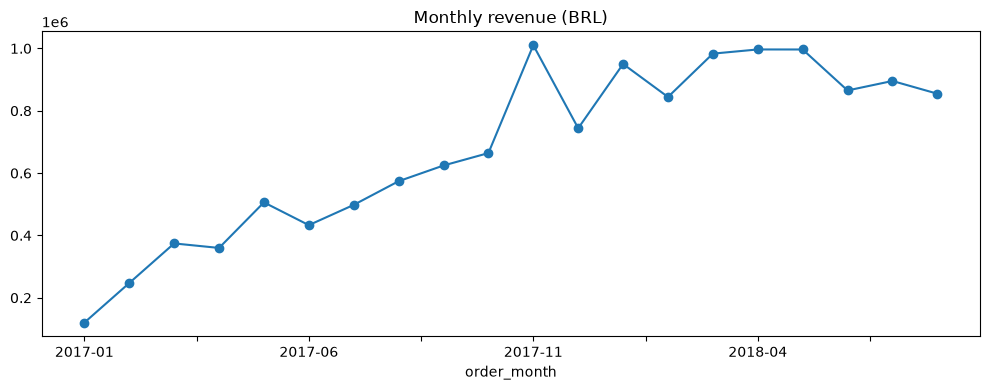

In [9]:
monthly["revenue"].plot(kind="line", marker="o", figsize=(10, 4), title="Monthly revenue (BRL)")
plt.tight_layout()
plt.savefig("../screenshots/monthly_revenue.png", dpi=150)
plt.savefig("../screenshots/top_categories.png", dpi=150)
plt.show()

customer_state
SP    5202955.0
RJ    1824093.0
MG    1585308.0
RS     750304.0
PR     683084.0
SC     520553.0
BA     511350.0
DF     302604.0
GO     294592.0
ES     275037.0
Name: price, dtype: float64